In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.chdir("/content/drive/MyDrive/Vehicle-type-classification")

Mounted at /content/drive


In [2]:
import json

with open("artifacts/class_indices.json") as f:
  class_indices = json.load(f)

idx_to_class = {
    v:k for k,v in class_indices.items()
}

In [3]:
import tensorflow as tf

model = tf.keras.models.load_model("models/vehicle_classifier_best.keras")

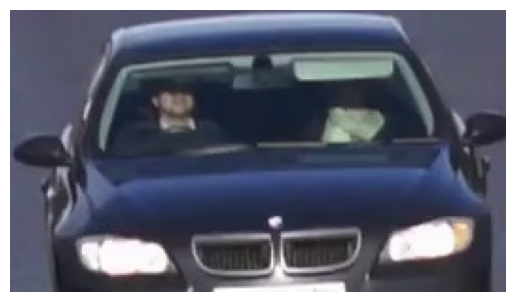

In [6]:
import cv2
import matplotlib.pyplot as plt

crop = cv2.imread("outputs/crops/vehicle_0.jpg")
crop_rgb = cv2.cvtColor(crop, cv2.COLOR_BGR2RGB)

plt.imshow(crop_rgb)
plt.axis("off")
plt.show()

In [7]:
import numpy as np

img = cv2.resize(crop_rgb, (224,224))
img = img.astype("float32")/255.0
img = np.expand_dims(img, axis=0)

In [8]:
preds = model.predict(img)
class_id = np.argmax(preds)
confidence = np.max(preds)

print(idx_to_class[class_id], confidence)

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
Car 0.9833914
